In [1]:
import sys
import os
import json
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'fly-2023-schaffer'

In [4]:
# file_ids = list(range(0, 12+1))
file_ids = [0]

path = os.path.join(read_utils.get_data_path(), 'brain')
filenames = [read_utils.get_filename(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

In [5]:
manual = True

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
boms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)[0] for filename in filenames]
hgms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)[0] for filename in filenames]

In [8]:
neuron_scores = assemble(boms_spn, hgms_spn)

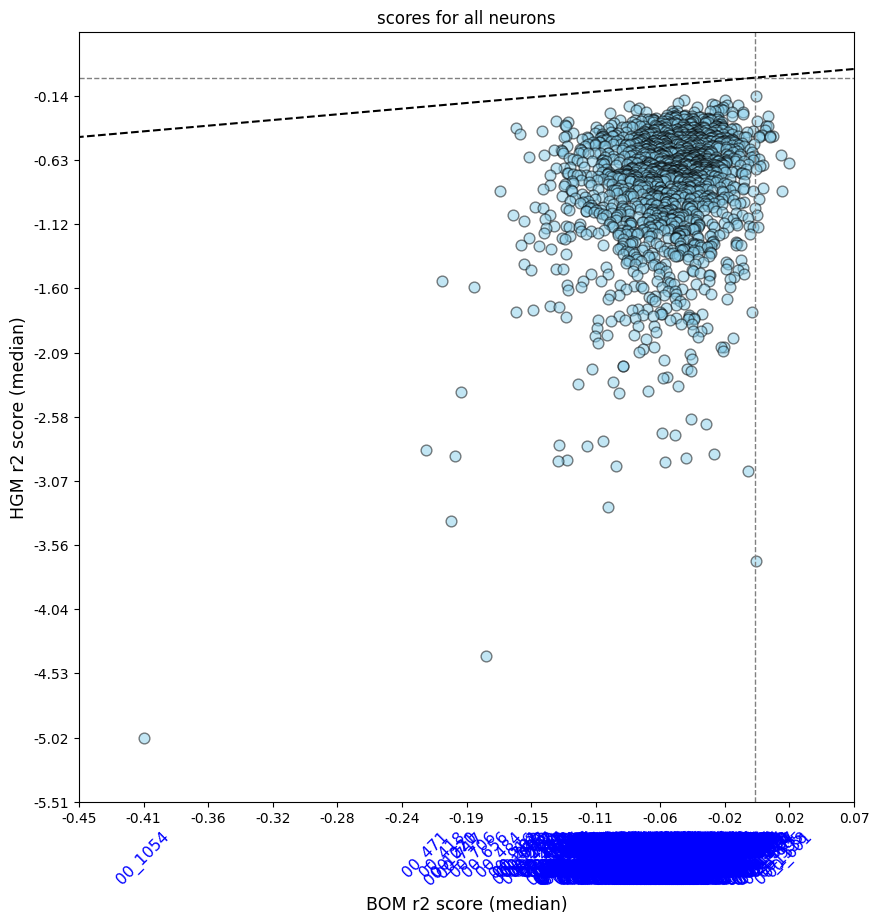

In [9]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None, force_medians=False
)

In [10]:
# plot_utils.plot_improvement_plot(
# 	neuron_scores, None,
# 	title='improvements for all neurons', limits=(-0.02, 0.02, -0.02, 0.02), force_medians=False,
# )

In [11]:
max_neurons = 10

relevant_hgm_n = list(reversed(sorted({key: value for key, value in neuron_scores.items() if 0 < value[0] < value[1]}.items(), key=lambda x: np.median(x[1][1]))))[:max_neurons]
relevant_hgm_n_labels = list([val[0] for val in relevant_hgm_n])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in relevant_hgm_n]))

ValueError: zero-size array to reduction operation minimum which has no identity

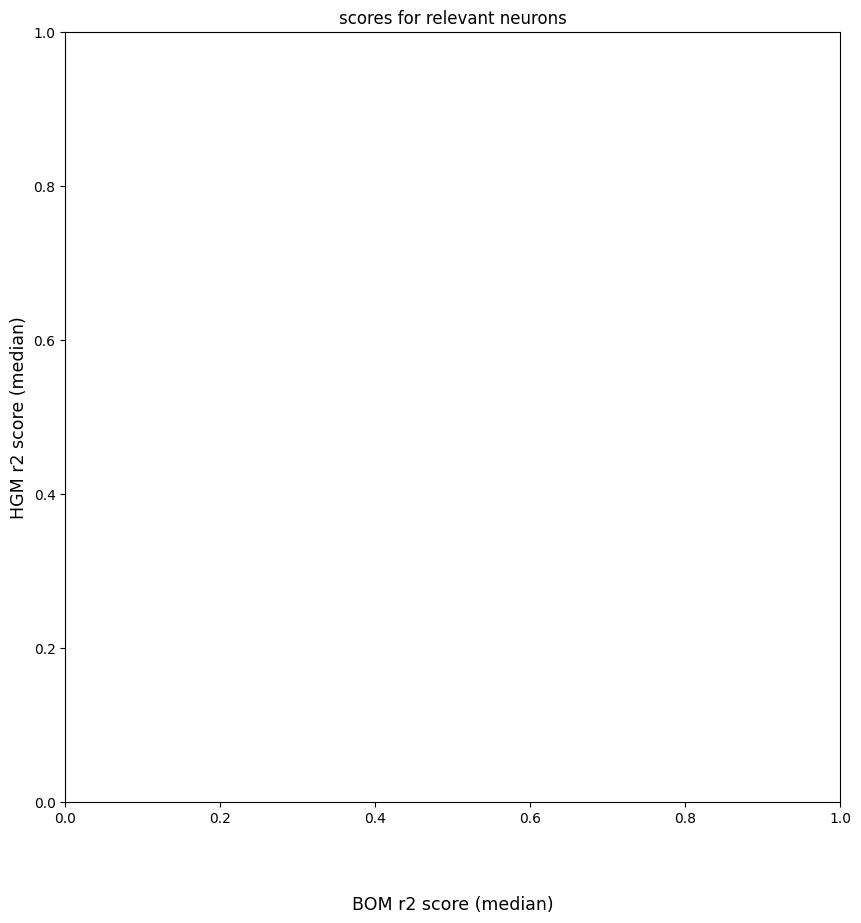

In [12]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n_labels}, None,
	title='scores for relevant neurons', limits=None, force_medians=False
)

In [ ]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in relevant_hgm_n_labels}, None,
	title='improvements for relevant neurons', limits=None, force_medians=False
)

In [ ]:
relevant_hgm_n_impr = list(reversed(sorted(relevant_hgm_n, key=lambda x: np.median(x[1][1] - x[1][0]))))
relevant_hgm_n_impr_labels = list([val[0] for val in relevant_hgm_n_impr])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in relevant_hgm_n_impr]))